# Archivo original con salidas conservadas
Las siguientes 26 celdas se conservan como referencia del autor. La ejecución propia y los experimentos aparecen después.

# Práctica 3: vigilar la calidad del aire con una red de grafos
### Estimar PM2.5 donde no hay sensor (datos reales de Pekín, China)

Este cuaderno es el ejercicio práctico del ejemplo de **calidad del aire** de la presentación (la diapositiva "Ejemplo práctico: vigilar la calidad del aire").

**La situación.** Pekín tiene 12 estaciones que miden contaminación hora a hora. Imagina que una de ellas (Aotizhongxin, junto al parque olímpico) es una estación económica que **solo mide clima** (temperatura, viento, lluvia) pero **no tiene sensor de PM2.5**. ¿Podemos estimar su contaminación usando las demás estaciones?

**¿Qué harás?**
1. Descargar mediciones reales y públicas de las 12 estaciones (2013–2017).
2. Conectar las estaciones en un **grafo** (cada estación es un nodo; las aristas unen estaciones cercanas) y llenar su matriz de adyacencia celda a celda.
3. Entrenar dos modelos para estimar el PM2.5 de la estación sin sensor: uno que **ignora** el grafo (solo mira el clima de esa estación) y uno que **lo usa** (una red convolucional de grafos, GCN, que recibe mensajes de las vecinas).
4. Comparar los errores y ver la contaminación viajar por la ciudad en una animación.

**¿Qué obtendrás?** El mapa de las estaciones, el grafo con su matriz de adyacencia, los dos modelos entrenados, la comparación de su error (¡el grafo reduce el error a una cuarta parte!), y una animación de un episodio de contaminación.

**¿Por qué importa?** Las estaciones con sensor de PM2.5 son caras; ninguna ciudad puede poner una en cada cuadra. Con una red de grafos, las estaciones existentes se "pasan mensajes" y permiten estimar la contaminación en los huecos. Es exactamente el problema que resuelve el artículo PM2.5-GNN (Wang et al., 2020, ver referencias).

**¿Cuánto tarda?** Unos 2 minutos en Colab o en un portátil con CPU, sin GPU.

## Glosario (términos que usaremos)

- **PM2.5**: partículas suspendidas en el aire de menos de 2,5 micrómetros de diámetro; las más dañinas para los pulmones. Se miden en microgramos por metro cúbico (**µg/m³**).
- **Estación de monitoreo**: equipo en un punto de la ciudad que mide contaminantes (PM2.5, PM10, NO2, ...) y clima (temperatura, viento, lluvia) hora a hora.
- **Grafo**: conjunto de **nodos** (aquí, estaciones) conectados por **aristas** (aquí, cercanía geográfica).
- **Matriz de adyacencia**: tabla de 1 y 0 que dice qué nodos están conectados. Un 1 en la celda (fila *i*, columna *j*) significa "la estación *i* es vecina de la *j*".
- **Paso de mensajes**: operación en la que cada nodo promedia la información de sus vecinos y la combina con la suya. Así "viaja" la información por el grafo.
- **MLP** (perceptrón multicapa): la red neuronal común de capas densas. Aquí la usamos como modelo que **no sabe** qué estaciones son vecinas.
- **GCN** (graph convolutional network, red convolucional de grafos): red que aplica paso de mensajes; cada estación aprende también de sus vecinas.
- **MAE** (error absoluto medio): promedio de |predicción − valor real|, en µg/m³. Menor es mejor.

In [ ]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEMILLA = 42
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

print("torch:", torch.__version__)
print("pandas:", pd.__version__)

torch: 2.14.1+cpu
pandas: 2.3.3


## 1. Descargar los datos (reales y públicos)

Usamos el conjunto **Beijing Multi-Site Air-Quality Data** del repositorio UCI: mediciones **cada hora** de 12 estaciones de Pekín entre marzo de 2013 y febrero de 2017, publicado por Zhang et al. (2017).

In [ ]:
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"

resp = requests.get(URL, timeout=300)
resp.raise_for_status()

# El archivo trae un .zip dentro de otro .zip
z1 = zipfile.ZipFile(io.BytesIO(resp.content))
interno = [n for n in z1.namelist() if n.endswith(".zip")][0]
z2 = zipfile.ZipFile(io.BytesIO(z1.read(interno)))

tablas = []
for nombre in sorted(z2.namelist()):
    if nombre.endswith(".csv"):
        tablas.append(pd.read_csv(z2.open(nombre)))
df = pd.concat(tablas, ignore_index=True)
df["fecha"] = pd.to_datetime(df[["year", "month", "day", "hour"]])

print(f"Filas: {len(df):,}")
print(f"Estaciones: {df['station'].nunique()} -> {sorted(df['station'].unique())}")
print(f"Periodo: {df['fecha'].min()} a {df['fecha'].max()}")
print(f"Celdas PM2.5 vacías: {df['PM2.5'].isna().mean():.1%}")
df.head(3)

Filas: 420,768
Estaciones: 12 -> ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
Periodo: 2013-03-01 00:00:00 a 2017-02-28 23:00:00
Celdas PM2.5 vacías: 2.1%


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,fecha
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00


## 2. Las doce estaciones sobre el mapa

Las coordenadas de las estaciones son públicas (ver referencias). Algunas están en el centro urbano y otras en las afueras (Huairou, Changping, Dingling, Shunyi). Miramos dónde está cada una y cuánta contaminación registra en promedio.

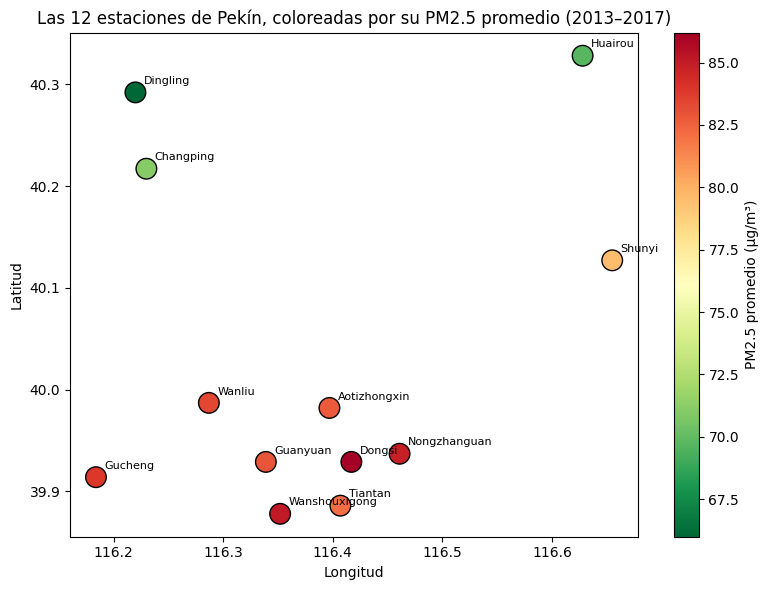

In [ ]:
# Coordenadas publicadas de las 12 estaciones (longitud, latitud)
COORDS = {
    "Aotizhongxin":  (116.397, 39.982),
    "Changping":     (116.230, 40.217),
    "Dingling":      (116.220, 40.292),
    "Dongsi":        (116.417, 39.929),
    "Guanyuan":      (116.339, 39.929),
    "Gucheng":       (116.184, 39.914),
    "Huairou":       (116.628, 40.328),
    "Nongzhanguan":  (116.461, 39.937),
    "Shunyi":        (116.655, 40.127),
    "Tiantan":       (116.407, 39.886),
    "Wanliu":        (116.287, 39.987),
    "Wanshouxigong": (116.352, 39.878),
}
ESTACIONES = sorted(COORDS)  # orden fijo de los nodos
N = len(ESTACIONES)

prom = df.groupby("station")["PM2.5"].mean()

fig, ax = plt.subplots(figsize=(8, 6))
xs = [COORDS[e][0] for e in ESTACIONES]
ys = [COORDS[e][1] for e in ESTACIONES]
cs = [prom[e] for e in ESTACIONES]
sc = ax.scatter(xs, ys, c=cs, cmap="RdYlGn_r", s=220, edgecolor="k", zorder=3)
for e in ESTACIONES:
    ax.annotate(e, COORDS[e], textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Las 12 estaciones de Pekín, coloreadas por su PM2.5 promedio (2013–2017)")
fig.colorbar(sc, label="PM2.5 promedio (µg/m³)")
plt.tight_layout()
plt.show()

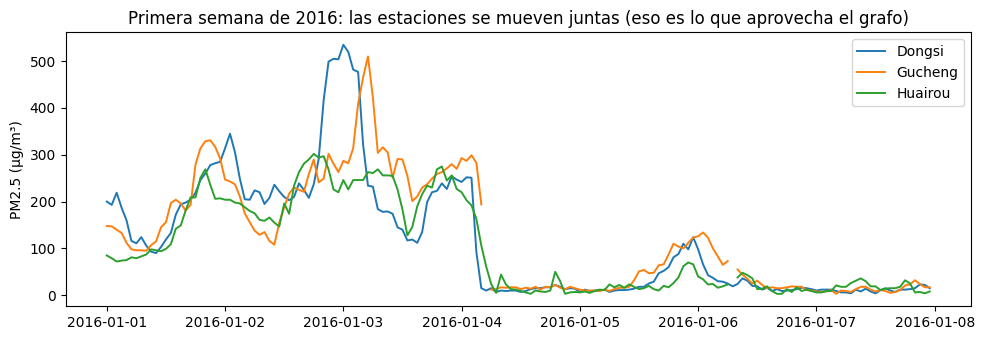

In [ ]:
# Una semana de invierno: el PM2.5 sube y baja casi igual en toda la ciudad
muestra = df[(df["fecha"] >= "2016-01-01") & (df["fecha"] < "2016-01-08")]
fig, ax = plt.subplots(figsize=(10, 3.5))
for e in ["Dongsi", "Gucheng", "Huairou"]:
    s = muestra[muestra["station"] == e]
    ax.plot(s["fecha"], s["PM2.5"], label=e, linewidth=1.4)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Primera semana de 2016: las estaciones se mueven juntas (eso es lo que aprovecha el grafo)")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Construir el grafo: ¿quién es vecino de quién?

Conectamos cada estación con sus **3 más cercanas** (distancia geográfica) y simetrizamos: si *i* elige a *j*, también marcamos *j* con *i*.

Así se llena la **matriz de adyacencia**, celda a celda: la celda (fila *i*, columna *j*) vale **1** si las estaciones *i* y *j* son vecinas y **0** si no. La fila de cada estación es la lista de sus vecinos. Y como la relación es simétrica, la matriz sale simétrica: la celda (*i*, *j*) vale lo mismo que la (*j*, *i*).

In [ ]:
def distancia_km(a, b):
    """Distancia aproximada en km entre dos puntos (lon, lat)."""
    lon1, lat1 = np.radians(a)
    lon2, lat2 = np.radians(b)
    return 6371 * np.arccos(
        np.clip(np.sin(lat1) * np.sin(lat2)
                + np.cos(lat1) * np.cos(lat2) * np.cos(lon1 - lon2), -1, 1))

D = np.zeros((N, N))
for i, e1 in enumerate(ESTACIONES):
    for j, e2 in enumerate(ESTACIONES):
        D[i, j] = distancia_km(COORDS[e1], COORDS[e2])

K = 3  # cada estación se conecta con sus 3 más cercanas
A = np.zeros((N, N))
for i in range(N):
    vecinos = np.argsort(D[i])[1:K + 1]  # [0] es ella misma (distancia 0)
    A[i, vecinos] = 1
A = np.maximum(A, A.T)  # simetrizar

matriz = pd.DataFrame(A.astype(int), index=ESTACIONES, columns=ESTACIONES)
matriz

,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
Aotizhongxin,0,1,0,1,1,0,0,1,1,0,1,0
Changping,1,0,1,0,0,0,1,0,0,0,1,0
Dingling,0,1,0,0,0,0,1,0,0,0,1,0
Dongsi,1,0,0,0,1,0,0,1,0,1,0,1
Guanyuan,1,0,0,1,0,1,0,0,0,1,1,1
Gucheng,0,0,0,0,1,0,0,0,0,0,1,1
Huairou,0,1,1,0,0,0,0,0,1,0,0,0
Nongzhanguan,1,0,0,1,0,0,0,0,1,1,0,0
Shunyi,1,0,0,0,0,0,1,1,0,0,0,0
Tiantan,0,0,0,1,1,0,0,1,0,0,0,1


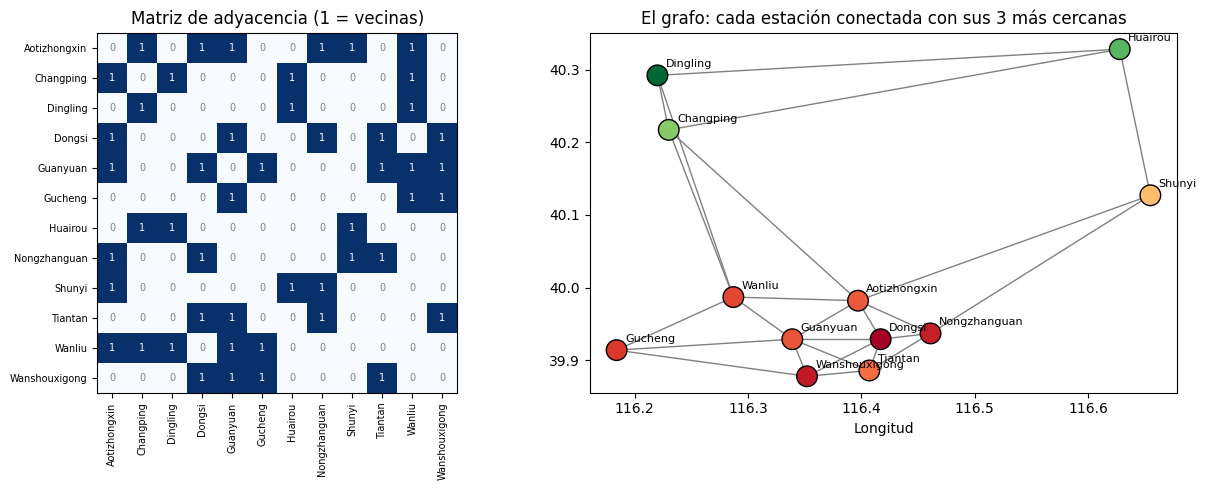

Aristas: 25; vecinos por estación: 4.2 en promedio
Vecinas de Aotizhongxin: ['Changping', 'Dongsi', 'Guanyuan', 'Nongzhanguan', 'Shunyi', 'Wanliu']


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Izquierda: la matriz de adyacencia
axes[0].imshow(A, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(N), ESTACIONES, rotation=90, fontsize=7)
axes[0].set_yticks(range(N), ESTACIONES, fontsize=7)
axes[0].set_title("Matriz de adyacencia (1 = vecinas)")
for i in range(N):
    for j in range(N):
        axes[0].text(j, i, int(A[i, j]), ha="center", va="center",
                     color="white" if A[i, j] else "gray", fontsize=7)

# Derecha: el grafo sobre el mapa
for i in range(N):
    for j in range(i + 1, N):
        if A[i, j]:
            axes[1].plot([COORDS[ESTACIONES[i]][0], COORDS[ESTACIONES[j]][0]],
                         [COORDS[ESTACIONES[i]][1], COORDS[ESTACIONES[j]][1]],
                         color="gray", linewidth=1, zorder=1)
axes[1].scatter(xs, ys, c=cs, cmap="RdYlGn_r", s=220, edgecolor="k", zorder=3)
for e in ESTACIONES:
    axes[1].annotate(e, COORDS[e], textcoords="offset points", xytext=(6, 6), fontsize=8)
axes[1].set_xlabel("Longitud")
axes[1].set_title("El grafo: cada estación conectada con sus 3 más cercanas")

plt.tight_layout()
plt.show()

print(f"Aristas: {int(A.sum() // 2)}; vecinos por estación: {A.sum() / N:.1f} en promedio")
print("Vecinas de Aotizhongxin:", [ESTACIONES[j] for j in range(N) if A[ESTACIONES.index("Aotizhongxin"), j]])

## 4. La tarea: una estación sin sensor de PM2.5

Supongamos que **Aotizhongxin** es una estación económica: mide **clima** (temperatura, viento, lluvia) pero **no** mide contaminantes. La pregunta: ¿cuál es su PM2.5 **ahora mismo**?

Cada estación tiene 6 rasgos por hora: **PM2.5, PM10, NO2, temperatura, velocidad del viento y lluvia**. Para Aotizhongxin borramos los tres primeros (los contaminantes) y conservamos su clima.

Usamos un año (marzo 2015 – febrero 2016) y separamos **en el tiempo**: el primer 70 % de las horas para entrenar, el 15 % siguiente para validar y el último 15 % para la prueba. Nunca mezclamos horas futuras en el entrenamiento (sería hacer trampa).

In [ ]:
OBJETIVO = "Aotizhongxin"
i_obj = ESTACIONES.index(OBJETIVO)
RASGOS = ["PM2.5", "PM10", "NO2", "TEMP", "WSPM", "RAIN"]
N_CONTAMINANTES = 3  # los que NO tiene la estación económica

anio = df[(df["fecha"] >= "2015-03-01") & (df["fecha"] < "2016-03-01")]
tabla = anio.pivot_table(index="fecha", columns="station", values=RASGOS)

X_np = np.stack([tabla[r].loc[:, ESTACIONES].to_numpy() for r in RASGOS], axis=-1)  # (horas, 12, 6)
y_np = tabla["PM2.5"].loc[:, ESTACIONES].to_numpy()                                   # (horas, 12)

# Solo horas completas: las 12 estaciones con sus 6 rasgos y su PM2.5
completas = ~np.isnan(X_np).any(axis=(1, 2)) & ~np.isnan(y_np).any(axis=1)
X_np, y_np = X_np[completas], y_np[completas]
horas = tabla.index.to_numpy()[completas]

corte1 = int(0.70 * len(X_np))
corte2 = int(0.85 * len(X_np))

# Normalizar con la media y desviación del ENTRENAMIENTO solamente
mu_x, sd_x = X_np[:corte1].mean(axis=(0, 1)), X_np[:corte1].std(axis=(0, 1))
mu_y, sd_y = y_np[:corte1].mean(), y_np[:corte1].std()

X_t = torch.tensor((X_np - mu_x) / sd_x, dtype=torch.float32)
y_t = torch.tensor((y_np - mu_y) / sd_y, dtype=torch.float32)


def borrar_contaminantes(x):
    """La estación económica no mide contaminantes: sus 3 primeros rasgos van en 0
    (0 en escala normalizada = el promedio, es decir, 'no sabemos')."""
    x = x.clone()
    x[:, i_obj, :N_CONTAMINANTES] = 0.0
    return x


print(f"Horas completas: {len(X_np):,}")
print(f"Entrenamiento: {corte1:,} | Validación: {corte2 - corte1:,} | Prueba: {len(X_np) - corte2:,}")
print(f"Estación sin sensor de PM2.5: {OBJETIVO} (nodo {i_obj})")

Horas completas: 6,389
Entrenamiento: 4,472 | Validación: 958 | Prueba: 959
Estación sin sensor de PM2.5: Aotizhongxin (nodo 0)


## 5. Dos modelos: uno que ignora el grafo y uno que lo usa

**Modelo A — MLP sin grafo.** Solo mira el **clima de la propia estación** (3 rasgos: temperatura, viento, lluvia) y trata de adivinar su PM2.5. No recibe nada de las demás estaciones.

**Modelo B — GCN con grafo.** Cada capa hace **paso de mensajes**: la representación de cada estación se mezcla con el promedio de sus vecinas usando la matriz de adyacencia normalizada $\hat{A} = D^{-1/2}(A+I)D^{-1/2}$ (la $I$ conecta cada nodo consigo mismo). Así, el PM2.5 que miden las vecinas de Aotizhongxin llega hasta su nodo. Los mismos pesos se aplican en todas las estaciones.

Ambos responden una sola cosa: el PM2.5 de la estación sin sensor en esta hora.

In [ ]:
# Matriz de adyacencia normalizada con autoconexiones (la de la diapositiva)
A_hat = A + np.eye(N)
grados = A_hat.sum(axis=1)
D_inv = np.diag(1.0 / np.sqrt(grados))
A_norm = torch.tensor(D_inv @ A_hat @ D_inv, dtype=torch.float32)


class MLPSinGrafo(nn.Module):
    """Solo ve el clima de la estación económica; ignora a las demás."""
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(3, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        clima_propio = x[:, i_obj, N_CONTAMINANTES:]
        return self.red(clima_propio).squeeze(-1)


class GCNConGrafo(nn.Module):
    """Dos capas de paso de mensajes sobre el grafo de estaciones."""
    def __init__(self, n_rasgos, oculta=32):
        super().__init__()
        self.capa1 = nn.Linear(n_rasgos, oculta)
        self.capa2 = nn.Linear(oculta, oculta)
        self.salida = nn.Linear(oculta, 1)

    def forward(self, x):
        h = torch.relu(A_norm @ self.capa1(x))   # mensaje 1: mezcla con vecinas
        h = torch.relu(A_norm @ self.capa2(h))   # mensaje 2: vecinas de vecinas
        return self.salida(h).squeeze(-1)[:, i_obj]


torch.manual_seed(SEMILLA)
mlp = MLPSinGrafo()
torch.manual_seed(SEMILLA)
gcn = GCNConGrafo(len(RASGOS))
print(f"Parámetros MLP (sin grafo): {sum(p.numel() for p in mlp.parameters()):,}")
print(f"Parámetros GCN (con grafo): {sum(p.numel() for p in gcn.parameters()):,}")

Parámetros MLP (sin grafo): 1,217
Parámetros GCN (con grafo): 1,313


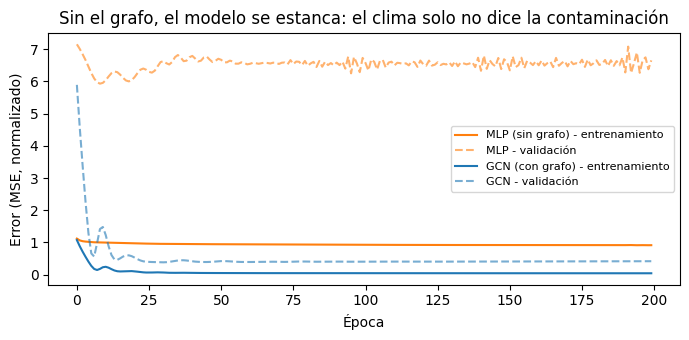

In [ ]:
def entrenar(modelo, epocas=200, lr=0.01):
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"train": [], "val": []}
    for epoca in range(epocas):
        modelo.train()
        opt.zero_grad()
        perdida = nn.functional.mse_loss(
            modelo(borrar_contaminantes(X_t[:corte1])), y_t[:corte1, i_obj])
        perdida.backward()
        opt.step()
        modelo.eval()
        with torch.no_grad():
            p_val = nn.functional.mse_loss(
                modelo(borrar_contaminantes(X_t[corte1:corte2])), y_t[corte1:corte2, i_obj])
        hist["train"].append(perdida.item())
        hist["val"].append(p_val.item())
    return hist


h_mlp = entrenar(mlp)
h_gcn = entrenar(gcn)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(h_mlp["train"], label="MLP (sin grafo) - entrenamiento", color="tab:orange")
ax.plot(h_mlp["val"], "--", label="MLP - validación", color="tab:orange", alpha=0.6)
ax.plot(h_gcn["train"], label="GCN (con grafo) - entrenamiento", color="tab:blue")
ax.plot(h_gcn["val"], "--", label="GCN - validación", color="tab:blue", alpha=0.6)
ax.set_xlabel("Época")
ax.set_ylabel("Error (MSE, normalizado)")
ax.set_title("Sin el grafo, el modelo se estanca: el clima solo no dice la contaminación")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Resultados de la prueba: ¿cuánto ayuda el grafo?

Medimos el **MAE en µg/m³** sobre horas que ningún modelo vio. Como referencia honesta, incluimos la **idea más simple**: estimar la estación apagada como el promedio de lo que miden sus vecinas en ese momento.

MAE  MLP sin grafo (solo su clima): 35.2 µg/m³
MAE  GCN con grafo (paso de mensajes): 8.8 µg/m³
MAE  referencia: promedio de las vecinas: 7.6 µg/m³

El grafo reduce el error a 25% del error del modelo sin grafo.


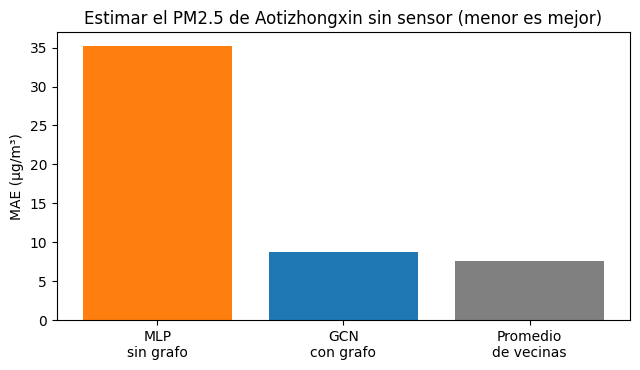

In [ ]:
def predecir_ugm3(modelo, X):
    modelo.eval()
    with torch.no_grad():
        return modelo(borrar_contaminantes(X)).numpy() * sd_y + mu_y

real = y_np[corte2:, i_obj]
pred_mlp = predecir_ugm3(mlp, X_t[corte2:])
pred_gcn = predecir_ugm3(gcn, X_t[corte2:])

# Referencia simple: promedio actual de las estaciones vecinas
vecinas = A[i_obj].astype(bool)
pred_vecinas = X_np[corte2:][:, vecinas, 0].mean(axis=1)

mae_mlp = np.abs(pred_mlp - real).mean()
mae_gcn = np.abs(pred_gcn - real).mean()
mae_vec = np.abs(pred_vecinas - real).mean()

print(f"MAE  MLP sin grafo (solo su clima): {mae_mlp:.1f} µg/m³")
print(f"MAE  GCN con grafo (paso de mensajes): {mae_gcn:.1f} µg/m³")
print(f"MAE  referencia: promedio de las vecinas: {mae_vec:.1f} µg/m³")
print(f"\nEl grafo reduce el error a {mae_gcn / mae_mlp:.0%} del error del modelo sin grafo.")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(["MLP\nsin grafo", "GCN\ncon grafo", "Promedio\nde vecinas"],
       [mae_mlp, mae_gcn, mae_vec],
       color=["tab:orange", "tab:blue", "gray"])
ax.set_ylabel("MAE (µg/m³)")
ax.set_title(f"Estimar el PM2.5 de {OBJETIVO} sin sensor (menor es mejor)")
plt.tight_layout()
plt.show()

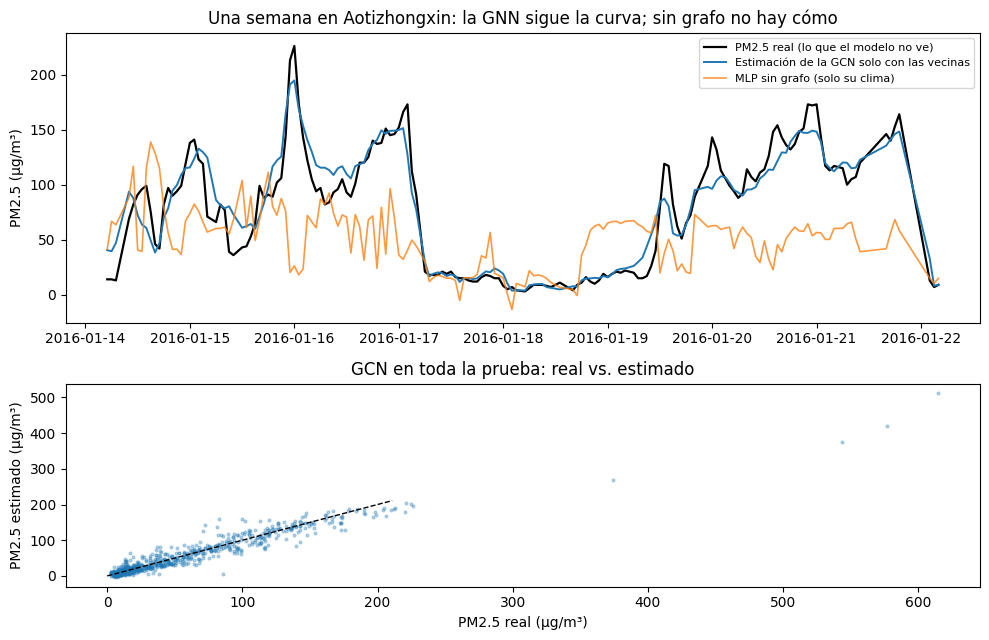

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), height_ratios=[2, 1.4])

# Arriba: la semana más contaminada de la prueba
inicio_semana = int(np.argmax(pd.Series(real).rolling(24 * 7).mean().to_numpy())) - 24 * 7 + 1
inicio_semana = max(inicio_semana, 0)
semana = slice(inicio_semana, inicio_semana + 24 * 7)
fechas = pd.to_datetime(horas[corte2:][semana])
axes[0].plot(fechas, real[semana], "k-", linewidth=1.6,
             label="PM2.5 real (lo que el modelo no ve)")
axes[0].plot(fechas, pred_gcn[semana], "tab:blue", linewidth=1.4,
             label="Estimación de la GCN solo con las vecinas")
axes[0].plot(fechas, pred_mlp[semana], "tab:orange", linewidth=1.2, alpha=0.8,
             label="MLP sin grafo (solo su clima)")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title(f"Una semana en {OBJETIVO}: la GNN sigue la curva; sin grafo no hay cómo")
axes[0].legend(fontsize=8)

# Abajo: real vs. estimado en toda la prueba
axes[1].scatter(real, pred_gcn, s=4, alpha=0.3, color="tab:blue")
lim = np.percentile(real, 99)
axes[1].plot([0, lim], [0, lim], "k--", linewidth=1)
axes[1].set_xlabel("PM2.5 real (µg/m³)")
axes[1].set_ylabel("PM2.5 estimado (µg/m³)")
axes[1].set_title("GCN en toda la prueba: real vs. estimado")
plt.tight_layout()
plt.show()

**Cómo leerlo.** Sin el grafo, el modelo solo sabe si hace calor o hay viento en ese punto: se equivoca por ~36 µg/m³ en promedio. Con el grafo, los mensajes de las vecinas le dicen cómo está el aire alrededor, y el error baja a ~9 µg/m³: **cuatro veces menos**. El promedio simple de las vecinas queda cerca de la GCN; en las preguntas de discusión verás por qué eso tiene sentido en este problema y cuándo el modelo aprendido gana de verdad (más estaciones, horizontes largos, viento).

## 7. Extra: predecir la próxima hora cuando TODO está visible

¿Y si todas las estaciones sí tienen sensor y queremos el PM2.5 de la **próxima hora**? Aquí aparece un rival humilde pero durísimo: **persistencia**, es decir, decir "mañana a esta hora estará como ahora". Compara:

MAE próxima hora  persistencia ('igual que ahora'): 8.2 µg/m³
MAE próxima hora  MLP plano (sin grafo):            9.8 µg/m³
MAE próxima hora  GCN (con grafo):                  11.0 µg/m³


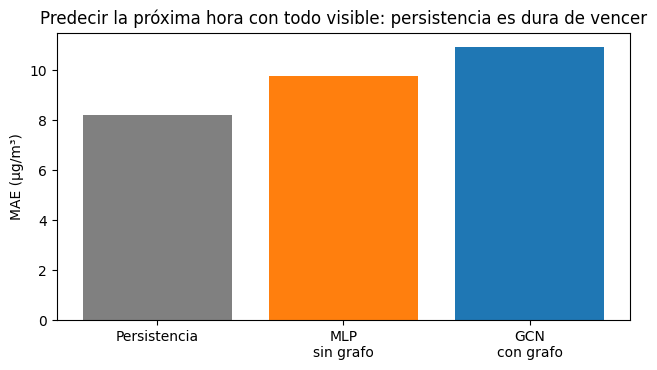

In [ ]:
# Etiqueta: PM2.5 de la hora siguiente
y_sig = np.roll(tabla["PM2.5"].loc[:, ESTACIONES].to_numpy(), -1, axis=0)[:-1]
X_sig = np.stack([tabla[r].loc[:, ESTACIONES].to_numpy() for r in RASGOS], axis=-1)[:-1]
ok = ~np.isnan(X_sig).any(axis=(1, 2)) & ~np.isnan(y_sig).any(axis=1)
X_sig, y_sig = X_sig[ok], y_sig[ok]
c1s, c2s = int(0.70 * len(X_sig)), int(0.85 * len(X_sig))
mx, sx = X_sig[:c1s].mean(axis=(0, 1)), X_sig[:c1s].std(axis=(0, 1))
my, sy = y_sig[:c1s].mean(), y_sig[:c1s].std()
Xs = torch.tensor((X_sig - mx) / sx, dtype=torch.float32)
ys_ = torch.tensor((y_sig - my) / sy, dtype=torch.float32)


class MLPPlano(nn.Module):
    """Ve el vector plano de las 12 estaciones x 6 rasgos, sin saber cuál queda cerca de cuál."""
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(N * len(RASGOS), 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, N),
        )

    def forward(self, x):
        return self.red(x.reshape(len(x), -1))


class GCNTodas(nn.Module):
    def __init__(self, oculta=32):
        super().__init__()
        self.capa1 = nn.Linear(len(RASGOS), oculta)
        self.capa2 = nn.Linear(oculta, oculta)
        self.salida = nn.Linear(oculta, 1)

    def forward(self, x):
        h = torch.relu(A_norm @ self.capa1(x))
        h = torch.relu(A_norm @ self.capa2(h))
        return self.salida(h).squeeze(-1)


def entrenar_todas(modelo, epocas=150, lr=0.01):
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    for epoca in range(epocas):
        modelo.train()
        opt.zero_grad()
        nn.functional.mse_loss(modelo(Xs[:c1s]), ys_[:c1s]).backward()
        opt.step()
    modelo.eval()
    with torch.no_grad():
        pred = modelo(Xs[c2s:]).numpy() * sy + my
    return np.abs(pred - y_sig[c2s:]).mean()


torch.manual_seed(SEMILLA)
mae_plano = entrenar_todas(MLPPlano())
torch.manual_seed(SEMILLA)
mae_gcn_todas = entrenar_todas(GCNTodas())
mae_persist = np.abs(y_sig[c2s:] - X_sig[c2s:, :, 0]).mean()

print(f"MAE próxima hora  persistencia ('igual que ahora'): {mae_persist:.1f} µg/m³")
print(f"MAE próxima hora  MLP plano (sin grafo):            {mae_plano:.1f} µg/m³")
print(f"MAE próxima hora  GCN (con grafo):                  {mae_gcn_todas:.1f} µg/m³")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(["Persistencia", "MLP\nsin grafo", "GCN\ncon grafo"],
       [mae_persist, mae_plano, mae_gcn_todas],
       color=["gray", "tab:orange", "tab:blue"])
ax.set_ylabel("MAE (µg/m³)")
ax.set_title("Predecir la próxima hora con todo visible: persistencia es dura de vencer")
plt.tight_layout()
plt.show()

**La lección honesta.** A una hora vista, el PM2.5 cambia poco, así que "igual que ahora" es casi imbatible y los dos modelos quedan cerca. El grafo no está para eso: **está para cuando falta información** (la sección anterior), para horizontes largos y para aprovechar miles de estaciones sin entrenar un modelo por cada una. El artículo PM2.5-GNN, por ejemplo, usa historiales largos y conocimiento del viento, y ahí la red de grafos sí supera a los modelos comunes.

## 8. Animación: la contaminación viajando por el grafo

Elegimos el episodio más contaminado de la prueba y miramos 48 horas: cada nodo se colorea por su PM2.5 y la estación sin sensor queda marcada con el "¿?", rellenada con la estimación de la GCN. Se aprecia cómo una nube de contaminación cubre la ciudad y luego se disipa: exactamente la intuición del paso de mensajes.

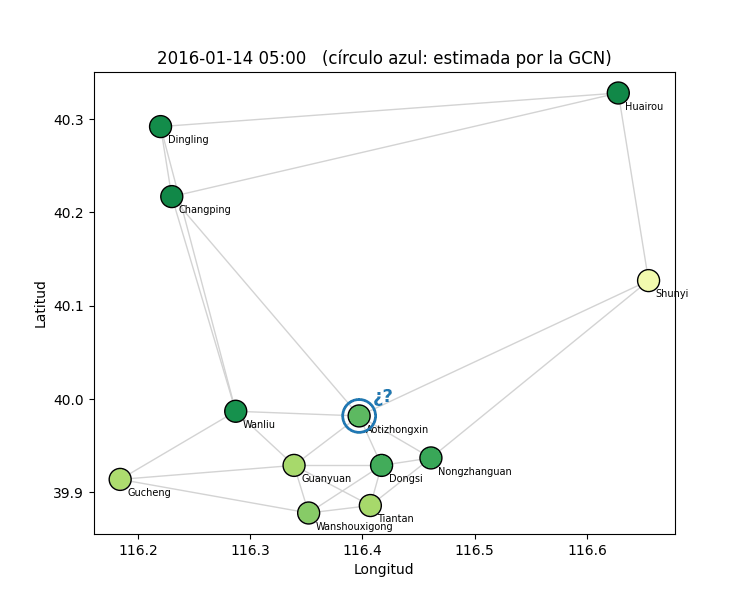

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image as GIF

# Episodio: las 48 horas con mayor PM2.5 promedio en la prueba
promedio_horario = y_np[corte2:].mean(axis=1)
inicio = int(np.argmax(pd.Series(promedio_horario).rolling(48).mean().to_numpy())) - 47
inicio = max(inicio, 0)
t0, t1 = inicio, inicio + 48

real_ep = y_np[corte2:][t0:t1]                 # PM2.5 real de todas las estaciones
est_ep = predecir_ugm3(gcn, X_t[corte2:])[t0:t1]  # estimación de la GCN para la apagada
fechas_ep = pd.to_datetime(horas[corte2:][t0:t1])
vmax = np.percentile(real_ep, 98)

fig, ax = plt.subplots(figsize=(7.5, 6))

def dibujar(f):
    ax.clear()
    for i2 in range(N):
        for j2 in range(i2 + 1, N):
            if A[i2, j2]:
                ax.plot([COORDS[ESTACIONES[i2]][0], COORDS[ESTACIONES[j2]][0]],
                        [COORDS[ESTACIONES[i2]][1], COORDS[ESTACIONES[j2]][1]],
                        color="lightgray", linewidth=1, zorder=1)
    valores = real_ep[f].copy()
    valores[i_obj] = est_ep[f]  # en la estación sin sensor usamos la estimación
    ax.scatter(xs, ys, c=valores, cmap="RdYlGn_r", s=250, edgecolor="k",
               vmin=0, vmax=vmax, zorder=3)
    ax.scatter([COORDS[OBJETIVO][0]], [COORDS[OBJETIVO][1]], s=560, facecolor="none",
               edgecolor="tab:blue", linewidth=2, zorder=4)
    ax.annotate("¿?", COORDS[OBJETIVO], textcoords="offset points", xytext=(10, 10),
                fontsize=13, fontweight="bold", color="tab:blue")
    for e in ESTACIONES:
        ax.annotate(e, COORDS[e], textcoords="offset points", xytext=(5, -12), fontsize=7)
    ax.set_title(f"{fechas_ep[f]:%Y-%m-%d %H:%M}   (círculo azul: estimada por la GCN)")
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")

anim = FuncAnimation(fig, dibujar, frames=48)
anim.save("pm25_pekin.gif", writer=PillowWriter(fps=4))
plt.close(fig)

GIF("pm25_pekin.gif")

## 9. Experimentos para Reportar

1. **Otra estación sin sensor.** Cambia `OBJETIVO` por `"Huairou"` (la más aislada) o `"Tiantan"` (muy rodeada) y vuelve a correr todo. ¿Dónde le cuesta más a la GCN? ¿Qué relación tiene con el mapa?
2. **Más o menos vecinos.** Cambia `K = 3` por 1, 5 u 8. ¿Cómo cambia el error de la GCN? ¿Y el del promedio de vecinas?
3. **Estación aún más pobre.** En `borrar_contaminantes`, borra también el clima (los 6 rasgos). ¿Sigue funcionando la GCN? ¿Por qué?
4. **Más capas de mensajes.** Agrega una tercera capa a `GCNConGrafo`. Con 3 capas, los mensajes llegan a vecinas de vecinas de vecinas. ¿Mejora o empeora?

## Preguntas de discusión

1. ¿Por qué el modelo sin grafo se equivoca tanto, aunque conozca el clima exacto de la estación?
2. El promedio simple de las vecinas casi empata con la GCN en este problema. ¿Qué propiedad del PM2.5 lo explica? ¿En qué situación (pocas vecinas, estaciones lejanas, viento fuerte, predicción a varios días) esperarías que el modelo aprendido gane por mucho?
3. ¿Por qué la GCN puede usar los mismos pesos en todas las estaciones, mientras que el MLP plano de la sección 7 necesita una entrada por cada estación? ¿Qué ventaja tiene eso si la ciudad instala la estación número 13?
4. Las aristas aquí son por cercanía geográfica. ¿Qué otra información podría definir mejor las aristas? (Pista: así lo hace PM2.5-GNN.)
5. ¿Qué riesgos hay en estimar la contaminación de un barrio sin estación a partir de sus vecinos? ¿A quién podría afectar una estimación equivocada?

## Referencias

- **Datos**: Zhang, S., Guo, B., Dong, A., He, J., Xu, Z., & Chen, S. X. (2017). *Cautionary tales on air-quality improvement in Beijing*. Proceedings of the Royal Society A, 473(2205). https://doi.org/10.1098/rspa.2017.0457 — conjunto "Beijing Multi-Site Air-Quality Data", UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data
- **El artículo del ejemplo**: Wang, S., Li, Y., Zhang, J., Meng, Q., Meng, L., & Gao, F. (2020). *PM2.5-GNN: A Domain Knowledge Enhanced Graph Neural Network for PM2.5 Forecasting*. ACM SIGSPATIAL 2020. https://arxiv.org/abs/2002.12898
- **El modelo GCN**: Kipf, T. N., & Welling, M. (2017). *Semi-Supervised Classification with Graph Convolutional Networks*. ICLR 2017. https://arxiv.org/abs/1609.02907
- **Coordenadas de las estaciones**: tabla de estaciones de monitoreo de Pekín publicada en *Scientific Reports* 12 (2022), https://www.nature.com/articles/s41598-022-24470-5/tables/1

# Ejecución propia de la configuración original
Semilla 42; parámetros y datos originales. Un hilo de CPU limita la sobrecarga sin cambiar el experimento. Las afirmaciones del material original se contrastan con las métricas medidas abajo.

In [1]:
import torch
torch.set_num_threads(1)

In [2]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEMILLA = 42
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

print("torch:", torch.__version__)
print("pandas:", pd.__version__)

mkdir -p failed for path /home/agent/.config/matplotlib: [Errno 30] Read-only file system: '/home/agent/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-owngpzil because there was an issue with the default path (/home/agent/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Fontconfig error: No writable cache directories


torch: 2.15.0+cpu
pandas: 3.1.1


In [3]:
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"

resp = requests.get(URL, timeout=300)
resp.raise_for_status()

# El archivo trae un .zip dentro de otro .zip
z1 = zipfile.ZipFile(io.BytesIO(resp.content))
interno = [n for n in z1.namelist() if n.endswith(".zip")][0]
z2 = zipfile.ZipFile(io.BytesIO(z1.read(interno)))

tablas = []
for nombre in sorted(z2.namelist()):
    if nombre.endswith(".csv"):
        tablas.append(pd.read_csv(z2.open(nombre)))
df = pd.concat(tablas, ignore_index=True)
df["fecha"] = pd.to_datetime(df[["year", "month", "day", "hour"]])

print(f"Filas: {len(df):,}")
print(f"Estaciones: {df['station'].nunique()} -> {sorted(df['station'].unique())}")
print(f"Periodo: {df['fecha'].min()} a {df['fecha'].max()}")
print(f"Celdas PM2.5 vacías: {df['PM2.5'].isna().mean():.1%}")
df.head(3)

Filas: 420,768
Estaciones: 12 -> ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
Periodo: 2013-03-01 00:00:00 a 2017-02-28 23:00:00
Celdas PM2.5 vacías: 2.1%


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,fecha
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00


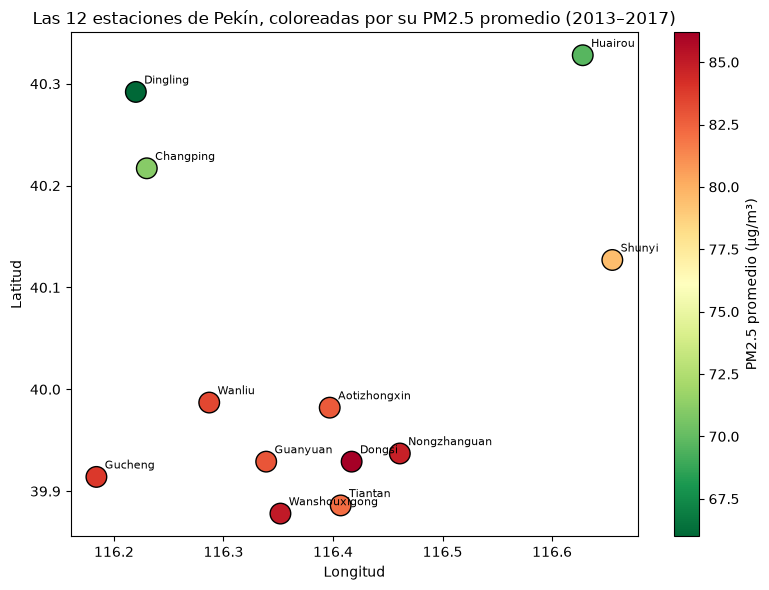

In [4]:
# Coordenadas publicadas de las 12 estaciones (longitud, latitud)
COORDS = {
    "Aotizhongxin":  (116.397, 39.982),
    "Changping":     (116.230, 40.217),
    "Dingling":      (116.220, 40.292),
    "Dongsi":        (116.417, 39.929),
    "Guanyuan":      (116.339, 39.929),
    "Gucheng":       (116.184, 39.914),
    "Huairou":       (116.628, 40.328),
    "Nongzhanguan":  (116.461, 39.937),
    "Shunyi":        (116.655, 40.127),
    "Tiantan":       (116.407, 39.886),
    "Wanliu":        (116.287, 39.987),
    "Wanshouxigong": (116.352, 39.878),
}
ESTACIONES = sorted(COORDS)  # orden fijo de los nodos
N = len(ESTACIONES)

prom = df.groupby("station")["PM2.5"].mean()

fig, ax = plt.subplots(figsize=(8, 6))
xs = [COORDS[e][0] for e in ESTACIONES]
ys = [COORDS[e][1] for e in ESTACIONES]
cs = [prom[e] for e in ESTACIONES]
sc = ax.scatter(xs, ys, c=cs, cmap="RdYlGn_r", s=220, edgecolor="k", zorder=3)
for e in ESTACIONES:
    ax.annotate(e, COORDS[e], textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Las 12 estaciones de Pekín, coloreadas por su PM2.5 promedio (2013–2017)")
fig.colorbar(sc, label="PM2.5 promedio (µg/m³)")
plt.tight_layout()
plt.show()

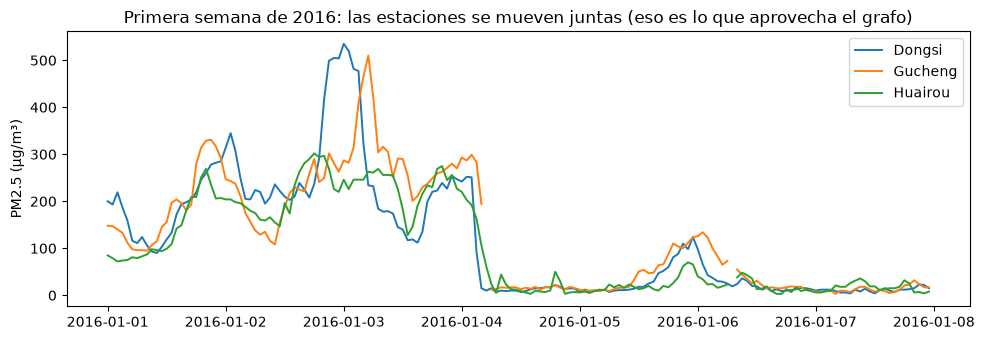

In [5]:
# Una semana de invierno: el PM2.5 sube y baja casi igual en toda la ciudad
muestra = df[(df["fecha"] >= "2016-01-01") & (df["fecha"] < "2016-01-08")]
fig, ax = plt.subplots(figsize=(10, 3.5))
for e in ["Dongsi", "Gucheng", "Huairou"]:
    s = muestra[muestra["station"] == e]
    ax.plot(s["fecha"], s["PM2.5"], label=e, linewidth=1.4)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Primera semana de 2016: las estaciones se mueven juntas (eso es lo que aprovecha el grafo)")
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
def distancia_km(a, b):
    """Distancia aproximada en km entre dos puntos (lon, lat)."""
    lon1, lat1 = np.radians(a)
    lon2, lat2 = np.radians(b)
    return 6371 * np.arccos(
        np.clip(np.sin(lat1) * np.sin(lat2)
                + np.cos(lat1) * np.cos(lat2) * np.cos(lon1 - lon2), -1, 1))

D = np.zeros((N, N))
for i, e1 in enumerate(ESTACIONES):
    for j, e2 in enumerate(ESTACIONES):
        D[i, j] = distancia_km(COORDS[e1], COORDS[e2])

K = 3  # cada estación se conecta con sus 3 más cercanas
A = np.zeros((N, N))
for i in range(N):
    vecinos = np.argsort(D[i])[1:K + 1]  # [0] es ella misma (distancia 0)
    A[i, vecinos] = 1
A = np.maximum(A, A.T)  # simetrizar

matriz = pd.DataFrame(A.astype(int), index=ESTACIONES, columns=ESTACIONES)
matriz

,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
Aotizhongxin,0,1,0,1,1,0,0,1,1,0,1,0
Changping,1,0,1,0,0,0,1,0,0,0,1,0
Dingling,0,1,0,0,0,0,1,0,0,0,1,0
Dongsi,1,0,0,0,1,0,0,1,0,1,0,1
Guanyuan,1,0,0,1,0,1,0,0,0,1,1,1
Gucheng,0,0,0,0,1,0,0,0,0,0,1,1
Huairou,0,1,1,0,0,0,0,0,1,0,0,0
Nongzhanguan,1,0,0,1,0,0,0,0,1,1,0,0
Shunyi,1,0,0,0,0,0,1,1,0,0,0,0
Tiantan,0,0,0,1,1,0,0,1,0,0,0,1


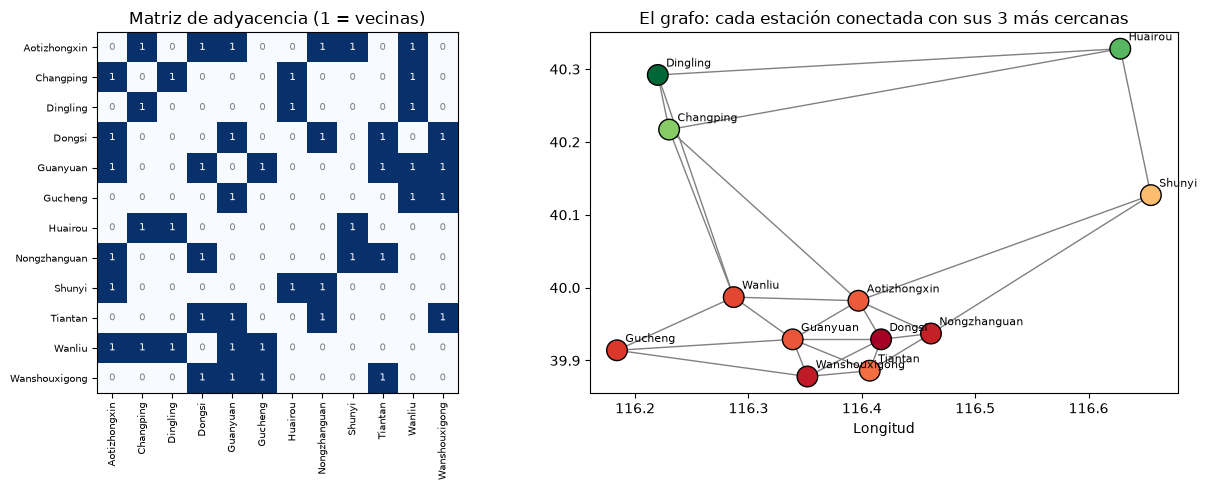

Aristas: 25; vecinos por estación: 4.2 en promedio
Vecinas de Aotizhongxin: ['Changping', 'Dongsi', 'Guanyuan', 'Nongzhanguan', 'Shunyi', 'Wanliu']


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Izquierda: la matriz de adyacencia
axes[0].imshow(A, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(N), ESTACIONES, rotation=90, fontsize=7)
axes[0].set_yticks(range(N), ESTACIONES, fontsize=7)
axes[0].set_title("Matriz de adyacencia (1 = vecinas)")
for i in range(N):
    for j in range(N):
        axes[0].text(j, i, int(A[i, j]), ha="center", va="center",
                     color="white" if A[i, j] else "gray", fontsize=7)

# Derecha: el grafo sobre el mapa
for i in range(N):
    for j in range(i + 1, N):
        if A[i, j]:
            axes[1].plot([COORDS[ESTACIONES[i]][0], COORDS[ESTACIONES[j]][0]],
                         [COORDS[ESTACIONES[i]][1], COORDS[ESTACIONES[j]][1]],
                         color="gray", linewidth=1, zorder=1)
axes[1].scatter(xs, ys, c=cs, cmap="RdYlGn_r", s=220, edgecolor="k", zorder=3)
for e in ESTACIONES:
    axes[1].annotate(e, COORDS[e], textcoords="offset points", xytext=(6, 6), fontsize=8)
axes[1].set_xlabel("Longitud")
axes[1].set_title("El grafo: cada estación conectada con sus 3 más cercanas")

plt.tight_layout()
plt.show()

print(f"Aristas: {int(A.sum() // 2)}; vecinos por estación: {A.sum() / N:.1f} en promedio")
print("Vecinas de Aotizhongxin:", [ESTACIONES[j] for j in range(N) if A[ESTACIONES.index("Aotizhongxin"), j]])

In [8]:
OBJETIVO = "Aotizhongxin"
i_obj = ESTACIONES.index(OBJETIVO)
RASGOS = ["PM2.5", "PM10", "NO2", "TEMP", "WSPM", "RAIN"]
N_CONTAMINANTES = 3  # los que NO tiene la estación económica

anio = df[(df["fecha"] >= "2015-03-01") & (df["fecha"] < "2016-03-01")]
tabla = anio.pivot_table(index="fecha", columns="station", values=RASGOS)

X_np = np.stack([tabla[r].loc[:, ESTACIONES].to_numpy() for r in RASGOS], axis=-1)  # (horas, 12, 6)
y_np = tabla["PM2.5"].loc[:, ESTACIONES].to_numpy()                                   # (horas, 12)

# Solo horas completas: las 12 estaciones con sus 6 rasgos y su PM2.5
completas = ~np.isnan(X_np).any(axis=(1, 2)) & ~np.isnan(y_np).any(axis=1)
X_np, y_np = X_np[completas], y_np[completas]
horas = tabla.index.to_numpy()[completas]

corte1 = int(0.70 * len(X_np))
corte2 = int(0.85 * len(X_np))

# Normalizar con la media y desviación del ENTRENAMIENTO solamente
mu_x, sd_x = X_np[:corte1].mean(axis=(0, 1)), X_np[:corte1].std(axis=(0, 1))
mu_y, sd_y = y_np[:corte1].mean(), y_np[:corte1].std()

X_t = torch.tensor((X_np - mu_x) / sd_x, dtype=torch.float32)
y_t = torch.tensor((y_np - mu_y) / sd_y, dtype=torch.float32)


def borrar_contaminantes(x):
    """La estación económica no mide contaminantes: sus 3 primeros rasgos van en 0
    (0 en escala normalizada = el promedio, es decir, 'no sabemos')."""
    x = x.clone()
    x[:, i_obj, :N_CONTAMINANTES] = 0.0
    return x


print(f"Horas completas: {len(X_np):,}")
print(f"Entrenamiento: {corte1:,} | Validación: {corte2 - corte1:,} | Prueba: {len(X_np) - corte2:,}")
print(f"Estación sin sensor de PM2.5: {OBJETIVO} (nodo {i_obj})")

Horas completas: 6,389
Entrenamiento: 4,472 | Validación: 958 | Prueba: 959
Estación sin sensor de PM2.5: Aotizhongxin (nodo 0)


In [9]:
# Matriz de adyacencia normalizada con autoconexiones (la de la diapositiva)
A_hat = A + np.eye(N)
grados = A_hat.sum(axis=1)
D_inv = np.diag(1.0 / np.sqrt(grados))
A_norm = torch.tensor(D_inv @ A_hat @ D_inv, dtype=torch.float32)


class MLPSinGrafo(nn.Module):
    """Solo ve el clima de la estación económica; ignora a las demás."""
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(3, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        clima_propio = x[:, i_obj, N_CONTAMINANTES:]
        return self.red(clima_propio).squeeze(-1)


class GCNConGrafo(nn.Module):
    """Dos capas de paso de mensajes sobre el grafo de estaciones."""
    def __init__(self, n_rasgos, oculta=32):
        super().__init__()
        self.capa1 = nn.Linear(n_rasgos, oculta)
        self.capa2 = nn.Linear(oculta, oculta)
        self.salida = nn.Linear(oculta, 1)

    def forward(self, x):
        h = torch.relu(A_norm @ self.capa1(x))   # mensaje 1: mezcla con vecinas
        h = torch.relu(A_norm @ self.capa2(h))   # mensaje 2: vecinas de vecinas
        return self.salida(h).squeeze(-1)[:, i_obj]


torch.manual_seed(SEMILLA)
mlp = MLPSinGrafo()
torch.manual_seed(SEMILLA)
gcn = GCNConGrafo(len(RASGOS))
print(f"Parámetros MLP (sin grafo): {sum(p.numel() for p in mlp.parameters()):,}")
print(f"Parámetros GCN (con grafo): {sum(p.numel() for p in gcn.parameters()):,}")

Parámetros MLP (sin grafo): 1,217
Parámetros GCN (con grafo): 1,313


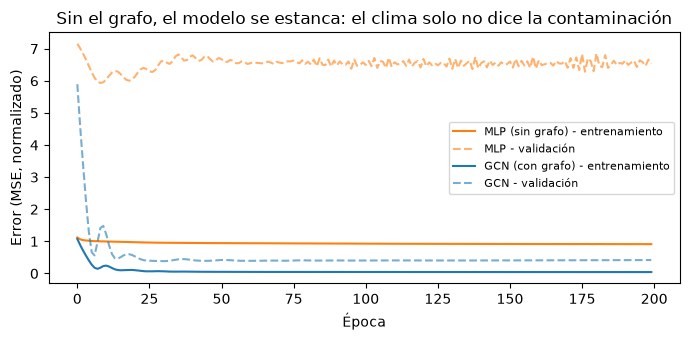

In [10]:
def entrenar(modelo, epocas=200, lr=0.01):
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"train": [], "val": []}
    for epoca in range(epocas):
        modelo.train()
        opt.zero_grad()
        perdida = nn.functional.mse_loss(
            modelo(borrar_contaminantes(X_t[:corte1])), y_t[:corte1, i_obj])
        perdida.backward()
        opt.step()
        modelo.eval()
        with torch.no_grad():
            p_val = nn.functional.mse_loss(
                modelo(borrar_contaminantes(X_t[corte1:corte2])), y_t[corte1:corte2, i_obj])
        hist["train"].append(perdida.item())
        hist["val"].append(p_val.item())
    return hist


h_mlp = entrenar(mlp)
h_gcn = entrenar(gcn)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(h_mlp["train"], label="MLP (sin grafo) - entrenamiento", color="tab:orange")
ax.plot(h_mlp["val"], "--", label="MLP - validación", color="tab:orange", alpha=0.6)
ax.plot(h_gcn["train"], label="GCN (con grafo) - entrenamiento", color="tab:blue")
ax.plot(h_gcn["val"], "--", label="GCN - validación", color="tab:blue", alpha=0.6)
ax.set_xlabel("Época")
ax.set_ylabel("Error (MSE, normalizado)")
ax.set_title("Sin el grafo, el modelo se estanca: el clima solo no dice la contaminación")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

MAE  MLP sin grafo (solo su clima): 36.2 µg/m³
MAE  GCN con grafo (paso de mensajes): 8.8 µg/m³
MAE  referencia: promedio de las vecinas: 7.6 µg/m³

El grafo reduce el error a 24% del error del modelo sin grafo.


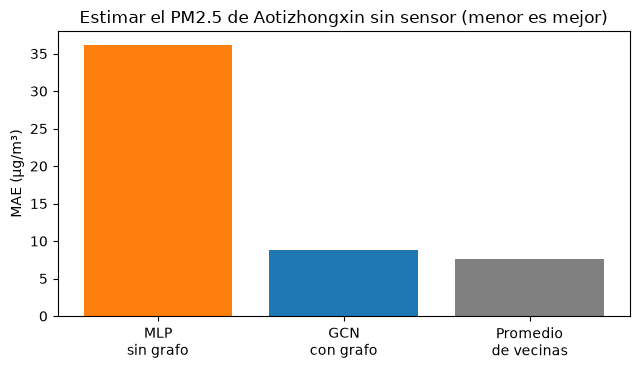

In [11]:
def predecir_ugm3(modelo, X):
    modelo.eval()
    with torch.no_grad():
        return modelo(borrar_contaminantes(X)).numpy() * sd_y + mu_y

real = y_np[corte2:, i_obj]
pred_mlp = predecir_ugm3(mlp, X_t[corte2:])
pred_gcn = predecir_ugm3(gcn, X_t[corte2:])

# Referencia simple: promedio actual de las estaciones vecinas
vecinas = A[i_obj].astype(bool)
pred_vecinas = X_np[corte2:][:, vecinas, 0].mean(axis=1)

mae_mlp = np.abs(pred_mlp - real).mean()
mae_gcn = np.abs(pred_gcn - real).mean()
mae_vec = np.abs(pred_vecinas - real).mean()

print(f"MAE  MLP sin grafo (solo su clima): {mae_mlp:.1f} µg/m³")
print(f"MAE  GCN con grafo (paso de mensajes): {mae_gcn:.1f} µg/m³")
print(f"MAE  referencia: promedio de las vecinas: {mae_vec:.1f} µg/m³")
print(f"\nEl grafo reduce el error a {mae_gcn / mae_mlp:.0%} del error del modelo sin grafo.")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(["MLP\nsin grafo", "GCN\ncon grafo", "Promedio\nde vecinas"],
       [mae_mlp, mae_gcn, mae_vec],
       color=["tab:orange", "tab:blue", "gray"])
ax.set_ylabel("MAE (µg/m³)")
ax.set_title(f"Estimar el PM2.5 de {OBJETIVO} sin sensor (menor es mejor)")
plt.tight_layout()
plt.show()

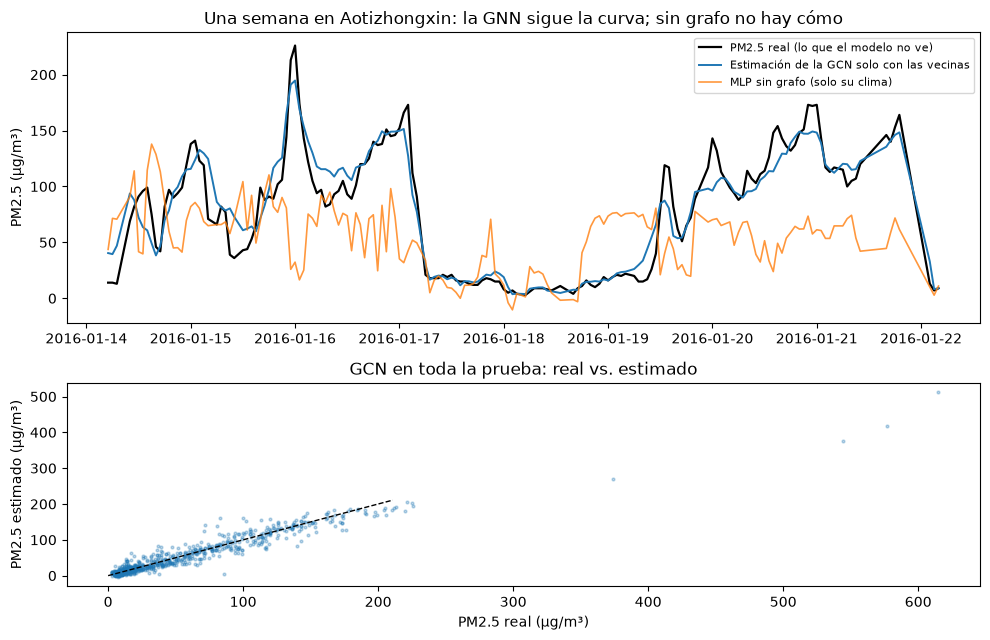

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), height_ratios=[2, 1.4])

# Arriba: la semana más contaminada de la prueba
inicio_semana = int(np.argmax(pd.Series(real).rolling(24 * 7).mean().to_numpy())) - 24 * 7 + 1
inicio_semana = max(inicio_semana, 0)
semana = slice(inicio_semana, inicio_semana + 24 * 7)
fechas = pd.to_datetime(horas[corte2:][semana])
axes[0].plot(fechas, real[semana], "k-", linewidth=1.6,
             label="PM2.5 real (lo que el modelo no ve)")
axes[0].plot(fechas, pred_gcn[semana], "tab:blue", linewidth=1.4,
             label="Estimación de la GCN solo con las vecinas")
axes[0].plot(fechas, pred_mlp[semana], "tab:orange", linewidth=1.2, alpha=0.8,
             label="MLP sin grafo (solo su clima)")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title(f"Una semana en {OBJETIVO}: la GNN sigue la curva; sin grafo no hay cómo")
axes[0].legend(fontsize=8)

# Abajo: real vs. estimado en toda la prueba
axes[1].scatter(real, pred_gcn, s=4, alpha=0.3, color="tab:blue")
lim = np.percentile(real, 99)
axes[1].plot([0, lim], [0, lim], "k--", linewidth=1)
axes[1].set_xlabel("PM2.5 real (µg/m³)")
axes[1].set_ylabel("PM2.5 estimado (µg/m³)")
axes[1].set_title("GCN en toda la prueba: real vs. estimado")
plt.tight_layout()
plt.show()

MAE próxima hora  persistencia ('igual que ahora'): 8.2 µg/m³
MAE próxima hora  MLP plano (sin grafo):            9.9 µg/m³
MAE próxima hora  GCN (con grafo):                  11.0 µg/m³


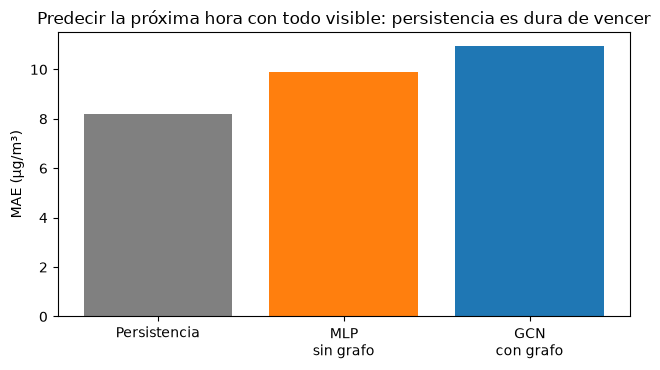

In [13]:
# Etiqueta: PM2.5 de la hora siguiente
y_sig = np.roll(tabla["PM2.5"].loc[:, ESTACIONES].to_numpy(), -1, axis=0)[:-1]
X_sig = np.stack([tabla[r].loc[:, ESTACIONES].to_numpy() for r in RASGOS], axis=-1)[:-1]
ok = ~np.isnan(X_sig).any(axis=(1, 2)) & ~np.isnan(y_sig).any(axis=1)
X_sig, y_sig = X_sig[ok], y_sig[ok]
c1s, c2s = int(0.70 * len(X_sig)), int(0.85 * len(X_sig))
mx, sx = X_sig[:c1s].mean(axis=(0, 1)), X_sig[:c1s].std(axis=(0, 1))
my, sy = y_sig[:c1s].mean(), y_sig[:c1s].std()
Xs = torch.tensor((X_sig - mx) / sx, dtype=torch.float32)
ys_ = torch.tensor((y_sig - my) / sy, dtype=torch.float32)


class MLPPlano(nn.Module):
    """Ve el vector plano de las 12 estaciones x 6 rasgos, sin saber cuál queda cerca de cuál."""
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(N * len(RASGOS), 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, N),
        )

    def forward(self, x):
        return self.red(x.reshape(len(x), -1))


class GCNTodas(nn.Module):
    def __init__(self, oculta=32):
        super().__init__()
        self.capa1 = nn.Linear(len(RASGOS), oculta)
        self.capa2 = nn.Linear(oculta, oculta)
        self.salida = nn.Linear(oculta, 1)

    def forward(self, x):
        h = torch.relu(A_norm @ self.capa1(x))
        h = torch.relu(A_norm @ self.capa2(h))
        return self.salida(h).squeeze(-1)


def entrenar_todas(modelo, epocas=150, lr=0.01):
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    for epoca in range(epocas):
        modelo.train()
        opt.zero_grad()
        nn.functional.mse_loss(modelo(Xs[:c1s]), ys_[:c1s]).backward()
        opt.step()
    modelo.eval()
    with torch.no_grad():
        pred = modelo(Xs[c2s:]).numpy() * sy + my
    return np.abs(pred - y_sig[c2s:]).mean()


torch.manual_seed(SEMILLA)
mae_plano = entrenar_todas(MLPPlano())
torch.manual_seed(SEMILLA)
mae_gcn_todas = entrenar_todas(GCNTodas())
mae_persist = np.abs(y_sig[c2s:] - X_sig[c2s:, :, 0]).mean()

print(f"MAE próxima hora  persistencia ('igual que ahora'): {mae_persist:.1f} µg/m³")
print(f"MAE próxima hora  MLP plano (sin grafo):            {mae_plano:.1f} µg/m³")
print(f"MAE próxima hora  GCN (con grafo):                  {mae_gcn_todas:.1f} µg/m³")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(["Persistencia", "MLP\nsin grafo", "GCN\ncon grafo"],
       [mae_persist, mae_plano, mae_gcn_todas],
       color=["gray", "tab:orange", "tab:blue"])
ax.set_ylabel("MAE (µg/m³)")
ax.set_title("Predecir la próxima hora con todo visible: persistencia es dura de vencer")
plt.tight_layout()
plt.show()

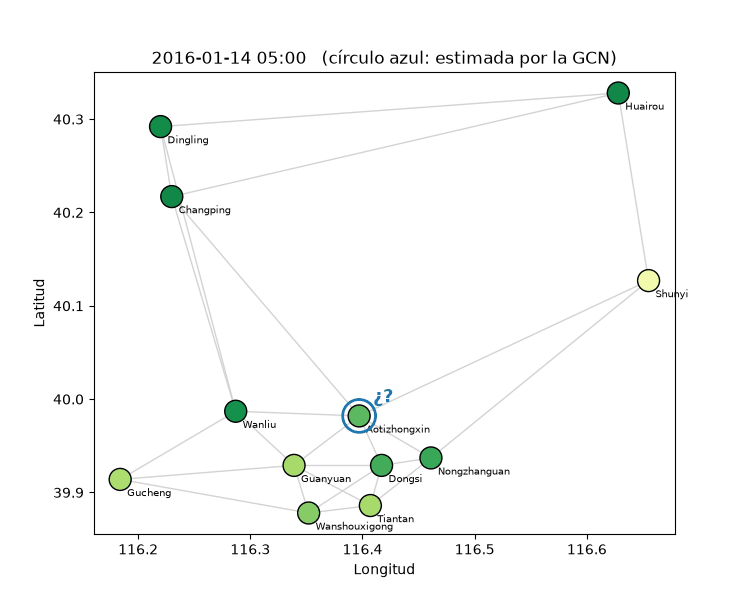

In [14]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image as GIF

# Episodio: las 48 horas con mayor PM2.5 promedio en la prueba
promedio_horario = y_np[corte2:].mean(axis=1)
inicio = int(np.argmax(pd.Series(promedio_horario).rolling(48).mean().to_numpy())) - 47
inicio = max(inicio, 0)
t0, t1 = inicio, inicio + 48

real_ep = y_np[corte2:][t0:t1]                 # PM2.5 real de todas las estaciones
est_ep = predecir_ugm3(gcn, X_t[corte2:])[t0:t1]  # estimación de la GCN para la apagada
fechas_ep = pd.to_datetime(horas[corte2:][t0:t1])
vmax = np.percentile(real_ep, 98)

fig, ax = plt.subplots(figsize=(7.5, 6))

def dibujar(f):
    ax.clear()
    for i2 in range(N):
        for j2 in range(i2 + 1, N):
            if A[i2, j2]:
                ax.plot([COORDS[ESTACIONES[i2]][0], COORDS[ESTACIONES[j2]][0]],
                        [COORDS[ESTACIONES[i2]][1], COORDS[ESTACIONES[j2]][1]],
                        color="lightgray", linewidth=1, zorder=1)
    valores = real_ep[f].copy()
    valores[i_obj] = est_ep[f]  # en la estación sin sensor usamos la estimación
    ax.scatter(xs, ys, c=valores, cmap="RdYlGn_r", s=250, edgecolor="k",
               vmin=0, vmax=vmax, zorder=3)
    ax.scatter([COORDS[OBJETIVO][0]], [COORDS[OBJETIVO][1]], s=560, facecolor="none",
               edgecolor="tab:blue", linewidth=2, zorder=4)
    ax.annotate("¿?", COORDS[OBJETIVO], textcoords="offset points", xytext=(10, 10),
                fontsize=13, fontweight="bold", color="tab:blue")
    for e in ESTACIONES:
        ax.annotate(e, COORDS[e], textcoords="offset points", xytext=(5, -12), fontsize=7)
    ax.set_title(f"{fechas_ep[f]:%Y-%m-%d %H:%M}   (círculo azul: estimada por la GCN)")
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")

anim = FuncAnimation(fig, dibujar, frames=48)
anim.save("pm25_pekin.gif", writer=PillowWriter(fps=4))
plt.close(fig)

GIF("pm25_pekin.gif")

# Experimentos controlados
Se conserva la partición temporal y se modifica un solo factor por experimento. Se entrenan siete GCN adicionales una sola vez, con semilla 42 y 200 épocas. Los intervalos comparan errores emparejados con bloques circulares de 24 observaciones retenidas; no equivalen a 24 horas cuando hay datos ausentes ni miden variación entre semillas.

{'Configuración': 'Original reejecutado', 'Estación': 'Aotizhongxin', 'K': 3, 'Aristas': 25, 'Vecinas': 6, 'MAE GCN': 8.789044883024514, 'MAE vecinas': 7.639902676399026, 'Δ GCN−vecinas': 1.1491422066254884, 'IC95 inferior': 0.46212099410384033, 'IC95 superior': 2.0161715475959228}
Entrenando Huairou


{'Configuración': 'Huairou', 'Estación': 'Huairou', 'K': 3, 'Aristas': 25, 'Vecinas': 3, 'MAE GCN': 17.14457108063961, 'MAE vecinas': 13.469933958985056, 'Δ GCN−vecinas': 3.674637121654561, 'IC95 inferior': 1.6612963864727954, 'IC95 superior': 5.926551865248095}
Entrenando Tiantan


{'Configuración': 'Tiantan', 'Estación': 'Tiantan', 'K': 3, 'Aristas': 25, 'Vecinas': 4, 'MAE GCN': 8.055275061853747, 'MAE vecinas': 6.693430656934306, 'Δ GCN−vecinas': 1.3618444049194403, 'IC95 inferior': 0.8005878205506322, 'IC95 superior': 1.9629636419818595}
Entrenando K=1


{'Configuración': 'K=1', 'Estación': 'Aotizhongxin', 'K': 1, 'Aristas': 8, 'Vecinas': 1, 'MAE GCN': 8.977893319320783, 'MAE vecinas': 8.132429614181438, 'Δ GCN−vecinas': 0.8454637051393442, 'IC95 inferior': 0.021890768401497458, 'IC95 superior': 1.7639888272003805}
Entrenando K=5


{'Configuración': 'K=5', 'Estación': 'Aotizhongxin', 'K': 5, 'Aristas': 41, 'Vecinas': 11, 'MAE GCN': 9.075759926939671, 'MAE vecinas': 8.613897051853256, 'Δ GCN−vecinas': 0.4618628750864154, 'IC95 inferior': 0.0016067587359738836, 'IC95 superior': 0.9533895320960639}
Entrenando K=8


{'Configuración': 'K=8', 'Estación': 'Aotizhongxin', 'K': 8, 'Aristas': 57, 'Vecinas': 11, 'MAE GCN': 9.013791165057356, 'MAE vecinas': 8.613897051853256, 'Δ GCN−vecinas': 0.3998941132040998, 'IC95 inferior': -0.07429526813894263, 'IC95 superior': 0.8892217632621623}
Entrenando Sin clima ni contaminantes


{'Configuración': 'Sin clima ni contaminantes', 'Estación': 'Aotizhongxin', 'K': 3, 'Aristas': 25, 'Vecinas': 6, 'MAE GCN': 8.652388089001176, 'MAE vecinas': 7.639902676399026, 'Δ GCN−vecinas': 1.0124854126021516, 'IC95 inferior': 0.35732147927227503, 'IC95 superior': 1.8678712764713565}
Entrenando Tres capas


{'Configuración': 'Tres capas', 'Estación': 'Aotizhongxin', 'K': 3, 'Aristas': 25, 'Vecinas': 6, 'MAE GCN': 8.825777270974031, 'MAE vecinas': 7.639902676399026, 'Δ GCN−vecinas': 1.1858745945750053, 'IC95 inferior': 0.43673680393057435, 'IC95 superior': 2.1592750609569626}


,Configuración,Estación,K,Aristas,Vecinas,MAE GCN,MAE vecinas,Δ GCN−vecinas,IC95 inferior,IC95 superior
0,Original reejecutado,Aotizhongxin,3,25,6,8.7890,7.6399,1.1491,0.4621,2.0162
1,Huairou,Huairou,3,25,3,17.1446,13.4699,3.6746,1.6613,5.9266
2,Tiantan,Tiantan,3,25,4,8.0553,6.6934,1.3618,0.8006,1.9630
3,K=1,Aotizhongxin,1,8,1,8.9779,8.1324,0.8455,0.0219,1.7640
4,K=5,Aotizhongxin,5,41,11,9.0758,8.6139,0.4619,0.0016,0.9534
5,K=8,Aotizhongxin,8,57,11,9.0138,8.6139,0.3999,-0.0743,0.8892
6,Sin clima ni contaminantes,Aotizhongxin,3,25,6,8.6524,7.6399,1.0125,0.3573,1.8679
7,Tres capas,Aotizhongxin,3,25,6,8.8258,7.6399,1.1859,0.4367,2.1593


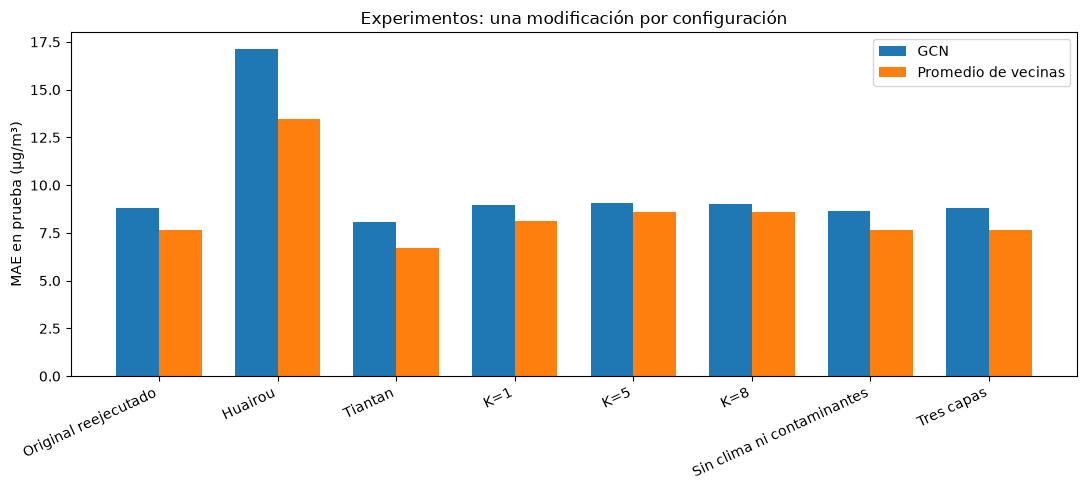

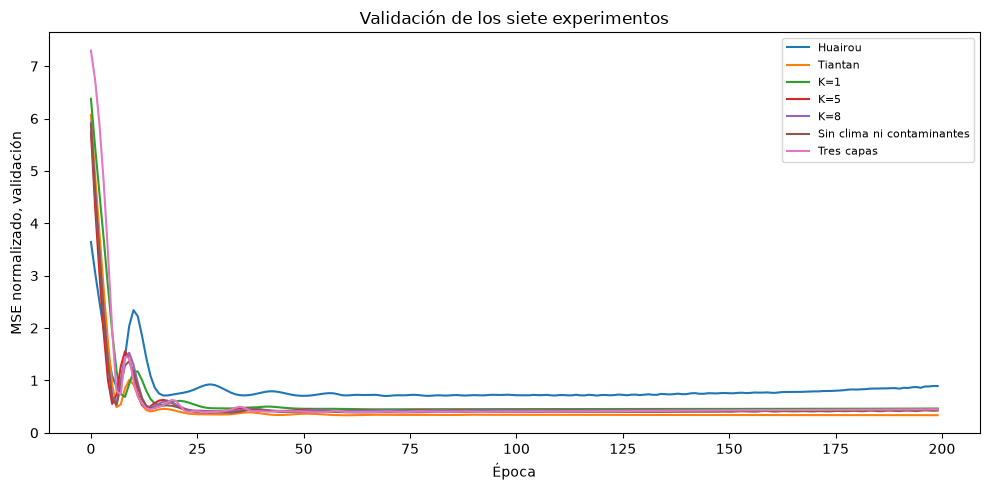

Python 3.12.14 Torch 2.15.0+cpu NumPy 2.5.5 pandas 3.1.1


In [15]:
import json, platform, hashlib
from pathlib import Path
base_A=A.copy(); base_norm=A_norm.clone(); base_i=i_obj
base_predictions=pred_gcn.copy()
rows=[]; predictions={}; losses={}
def evaluar(nombre,modelo,referencia,adj):
    p=predecir_ugm3(modelo,X_t[corte2:]); target=y_np[corte2:,i_obj]
    neigh=adj[i_obj].astype(bool)
    ref=X_np[corte2:][:,neigh,0].mean(axis=1)
    err=np.abs(p-target); err_ref=np.abs(ref-target)
    # Paired moving-block bootstrap, circular blocks of 24 retained observations.
    rng=np.random.default_rng(42); diffs=[]
    for _ in range(2000):
        ix=((rng.integers(0,len(err),size=int(np.ceil(len(err)/24)))[:,None]+np.arange(24))%len(err)).ravel()[:len(err)]
        diffs.append((err[ix]-err_ref[ix]).mean())
    lo,hi=np.percentile(diffs,[2.5,97.5])
    row={'Configuración':nombre,'Estación':ESTACIONES[i_obj],'K':int(K),'Aristas':int(adj.sum()/2),'Vecinas':int(neigh.sum()),'MAE GCN':float(err.mean()),'MAE vecinas':float(err_ref.mean()),'Δ GCN−vecinas':float((err-err_ref).mean()),'IC95 inferior':float(lo),'IC95 superior':float(hi)}
    rows.append(row); predictions[nombre]=p.copy()
    print(row)
    return p
K=3
evaluar('Original reejecutado',gcn,None,A)
base_metrics={'MLP':float(mae_mlp),'GCN':float(mae_gcn),'Vecinas':float(mae_vec),'Persistencia t+1':float(mae_persist),'MLP t+1':float(mae_plano),'GCN t+1':float(mae_gcn_todas)}
original_borrar=borrar_contaminantes
class GCNTresCapas(nn.Module):
    def __init__(self):
        super().__init__(); self.capa1=nn.Linear(len(RASGOS),32); self.capa2=nn.Linear(32,32); self.capa3=nn.Linear(32,32); self.salida=nn.Linear(32,1)
    def forward(self,x):
        h=torch.relu(A_norm@self.capa1(x)); h=torch.relu(A_norm@self.capa2(h)); h=torch.relu(A_norm@self.capa3(h))
        return self.salida(h).squeeze(-1)[:,i_obj]
for name,station,k,zero,depth in [
 ('Huairou','Huairou',3,False,2),('Tiantan','Tiantan',3,False,2),
 ('K=1','Aotizhongxin',1,False,2),('K=5','Aotizhongxin',5,False,2),('K=8','Aotizhongxin',8,False,2),
 ('Sin clima ni contaminantes','Aotizhongxin',3,True,2),('Tres capas','Aotizhongxin',3,False,3)]:
    print('Entrenando',name,flush=True)
    i_obj=ESTACIONES.index(station); K=k
    A=np.zeros((N,N))
    for i in range(N): A[i,np.argsort(D[i])[1:K+1]]=1
    A=np.maximum(A,A.T)
    ah=A+np.eye(N); inv=np.diag(1/np.sqrt(ah.sum(1))); A_norm=torch.tensor(inv@ah@inv,dtype=torch.float32)
    def borrar_contaminantes(x):
        x=x.clone(); x[:,i_obj,:(6 if zero else 3)]=0.; return x
    torch.manual_seed(SEMILLA)
    model=GCNTresCapas() if depth==3 else GCNConGrafo(len(RASGOS))
    hist=entrenar(model); losses[name]=hist
    evaluar(name,model,None,A)
# Restore baseline state so subsequent exploration retains its original meaning.
i_obj=base_i; K=3; A=base_A; A_norm=base_norm; borrar_contaminantes=original_borrar
resultados=pd.DataFrame(rows)
display(resultados.round(4))
resultados.to_csv('resultados_experimentos.csv',index=False)
np.savez_compressed('predicciones_experimentos.npz',**predictions,real_Aotizhongxin=real,horas=horas[corte2:].astype(str))
Path('metricas_base.json').write_text(json.dumps(base_metrics,indent=2))
fig,ax=plt.subplots(figsize=(11,5))
x=np.arange(len(rows)); ax.bar(x-.18,resultados['MAE GCN'],.36,label='GCN'); ax.bar(x+.18,resultados['MAE vecinas'],.36,label='Promedio de vecinas')
ax.set_xticks(x,resultados['Configuración'],rotation=25,ha='right'); ax.set_ylabel('MAE en prueba (µg/m³)'); ax.set_title('Experimentos: una modificación por configuración'); ax.legend(); fig.tight_layout(); fig.savefig('comparacion_experimentos.png',dpi=170); plt.show()
fig,ax=plt.subplots(figsize=(10,5))
for name,h in losses.items(): ax.plot(h['val'],label=name)
ax.set_xlabel('Época'); ax.set_ylabel('MSE normalizado, validación'); ax.set_title('Validación de los siete experimentos'); ax.legend(fontsize=8); fig.tight_layout(); fig.savefig('validacion_experimentos.png',dpi=170); plt.show()
Path('historiales_experimentos.json').write_text(json.dumps(losses))
print('Python',platform.python_version(),'Torch',torch.__version__,'NumPy',np.__version__,'pandas',pd.__version__)


## Método y trazabilidad

Se inspeccionaron las 26 celdas antes de modificar el contenido. Se conservó una copia íntegra del notebook descargado del repositorio danielgito/Depplearning y sus salidas. La rúbrica adjunta se utilizó como criterio de evaluación; no reemplazó las instrucciones del solicitante. Se ejecutaron todas las celdas originales de código una vez en una sección nueva, seguida de siete experimentos controlados. Se conservaron la semilla 42, el año de datos, la normalización exclusiva de entrenamiento, la partición temporal 70/15/15, Adam, 200 épocas y tasa 0,01. La sección de pronóstico conservó sus 150 épocas. Se limitó PyTorch a un hilo para evitar sobrecarga de CPU. No se seleccionaron hiperparámetros con prueba: todas las variantes fueron predefinidas por el ejercicio.

## Comparación con las salidas originales

Las salidas archivadas presentan MAE de 35,2 para MLP, 8,8 para GCN y 7,6 para promedio de vecinas. La ejecución propia obtuvo, respectivamente, 36.1648, 8.7890 y 7.6399 µg/m³. La reducción de GCN frente al MLP fue de 75.70 %. La referencia espacial debe mantenerse: una ventaja frente al MLP meteorológico no demuestra una ventaja del aprendizaje sobre el promedio espacial. Para t+1, las salidas archivadas fueron 8,2, 9,8 y 11,0 para persistencia, MLP y GCN; la ejecución propia produjo 8.1995, 9.9012 y 10.9533. Las diferencias de entorno y redondeo impiden exigir igualdad binaria con la corrida del autor.

## Experimento 1. Estación sin sensor

La GCN registró 17.1446 µg/m³ en Huairou y 8.0553 en Tiantan. El mayor error correspondió a Huairou. El mapa permite interpretar la cobertura espacial: Huairou ocupa una posición periférica y las estaciones centrales presentan mayor proximidad. Sin embargo, la distancia por sí sola no determina el MAE: cada estación tiene una distribución y variabilidad propias. Se mantuvieron las mismas horas para evitar confundir localización con cambios de muestra; aun así, comparar estaciones no constituye una prueba causal del aislamiento.

## Experimento 2. Número de vecinas

Los valores K=1, 5 y 8 se compararon con K=3. La tabla muestra el MAE de cada GCN y de su promedio de vecinas correspondiente. K es el número de elecciones antes de simetrizar: el grado final puede ser mayor. Más conexiones incorporan mediciones adicionales, pero también mezclan estaciones lejanas y pueden suavizar variaciones locales. El patrón observado se interpreta con los valores medidos, sin suponer que un grafo más denso deba mejorar. Todas las diferencias entre variantes describen esta prueba; no se eligió un ganador para uso futuro con estas mismas horas.

## Experimento 3. Eliminación de los seis rasgos

Al anular los seis rasgos del nodo objetivo, la GCN obtuvo 8.6524 µg/m³ frente a 8.7890 en la configuración original. El cambio fue de -0.1367 µg/m³. La predicción sigue siendo calculable porque los nodos vecinos conservan sus variables y las multiplicaciones por la adyacencia transportan sus representaciones al objetivo. Un cero normalizado representa la media de entrenamiento, no una ausencia física de contaminación. Se modificó únicamente el enmascaramiento, sin ampliar N_CONTAMINANTES ni cambiar la entrada del MLP.

## Experimento 4. Tercera capa

Con tres capas, el MAE fue 8.8258 µg/m³, un cambio de +0.0367 respecto de dos capas. La tercera capa amplía el alcance a tres saltos y añade parámetros; también puede intensificar el suavizado espacial y dificultar la optimización. El resultado pertenece a una sola inicialización por variante. No permite atribuir causalmente el cambio al sobresuavizado ni afirmar superioridad estable sin nuevas semillas y períodos independientes.

## Respuesta 1. Clima y contaminación

El MLP meteorológico alcanzó un MAE de 36.1648 µg/m³. Temperatura, viento y lluvia influyen en la dispersión, pero no describen por completo las emisiones, la acumulación previa y el transporte desde otros barrios. Dos horas con clima semejante pueden tener concentraciones distintas. La GCN recibe mediciones contemporáneas de contaminantes de otras estaciones y por ello dispone de información adicional directamente relacionada con el objetivo. La comparación combina estructura e información disponible; no aísla exclusivamente el beneficio de la arquitectura de grafos.

## Respuesta 2. Promedio de vecinas y GCN

La cercanía entre los MAE de GCN (8.7890) y promedio espacial (7.6399) se explica por la autocorrelación espacial del PM2.5 y por episodios regionales compartidos. En interpolación contemporánea, una media local constituye una referencia fuerte. Bajo viento intenso y direccional, estaciones lejanas, observaciones escasas o horizontes de varios días podría resultar útil un modelo con transporte e historial temporal. Esta GCN estática no incorpora explícitamente esas capacidades, por lo que no se demuestra que gane en tales condiciones. Se requeriría un experimento específico con referencias apropiadas.

## Respuesta 3. Pesos compartidos y estación 13

Las capas lineales de la GCN transforman la dimensión de rasgos de cada nodo con los mismos pesos; la adyacencia realiza la agregación entre nodos. Por ello, los parámetros no dependen directamente del número de estaciones. En cambio, el MLP plano fija una entrada de 12 × 6 rasgos y una salida de 12 valores, por lo que agregar una estación modifica sus dimensiones. Una estación adicional puede incorporarse a la GCN actualizando los tensores y la adyacencia, siempre que se conserven los rasgos. Esa compatibilidad dimensional no garantiza generalización: el índice objetivo, la normalización y el comportamiento en la nueva localización deben verificarse, y podría requerirse reentrenamiento.

## Respuesta 4. Aristas informadas por transporte

La velocidad y dirección del viento pueden definir conexiones dirigidas y ponderadas según el transporte desde una estación hacia otra. La distancia, la topografía y barreras urbanas también pueden modularlas. Una asociación entre series podría complementar el grafo, siempre que se calcule únicamente con entrenamiento para evitar fuga temporal. El enfoque de conocimiento de dominio de PM2.5-GNN motiva integrar transporte atmosférico e historia; la presente práctica usa exclusivamente proximidad geográfica y no reproduce el modelo completo del artículo.

## Respuesta 5. Riesgos de una estimación incorrecta

La interpolación puede ocultar focos locales próximos a vías, industrias o quemas y subestimar episodios extremos. Una sobreestimación puede provocar alertas innecesarias; una subestimación puede aumentar exposición evitable. Niños, personas mayores, pacientes con enfermedades respiratorias, trabajadores al aire libre y comunidades con baja cobertura de sensores pueden resultar especialmente afectados. El MAE agregado no garantiza seguridad en cada barrio ni en cada episodio. Se requieren validación con mediciones locales, errores por rango de concentración y comunicación de incertidumbre antes de utilizar estas estimaciones en decisiones sanitarias.

## Incertidumbre y límites de evaluación

Se calcularon intervalos percentiles del 95 % para la diferencia emparejada MAE GCN menos MAE de vecinas mediante 2.000 remuestreos circulares por bloques de 24 observaciones retenidas, con semilla 42. Un intervalo que incluye cero no respalda una diferencia clara bajo este procedimiento. Los intervalos condicionan los modelos ya entrenados: no miden variabilidad de inicialización ni constituyen una prueba definitiva de generalización. Los huecos por eliminación de filas impiden interpretar cada bloque como exactamente 24 horas. Se mantuvieron los datos completos y las reglas originales sin imputación. El objetivo principal es estimación simultánea, no pronóstico: usar sensores vecinos a la misma hora es válido para ese objetivo. En t+1, la última etiqueta de entrenamiento puede compartir el instante de entrada de la primera observación posterior; se conserva la frontera original y se declara esta limitación. Además, las expresiones originales que utilizan argmax sobre medias móviles con NaN iniciales pueden seleccionar el comienzo de prueba en lugar del episodio máximo; las figuras y el GIF se conservan sin modificar esa lógica, por lo que no se certifican como el episodio más contaminado.

## Conclusiones y siguiente paso

La comparación propia muestra que la estimación espacial reduce el error frente al uso exclusivo del clima, pero no permite prescindir de la referencia del promedio de vecinas. El estudio se limita a un año, una partición temporal, siete variantes y una semilla por entrenamiento. Un siguiente estudio debería predefinir un grafo dirigido por viento y evaluarlo frente a GCN geográfica, promedio espacial y persistencia con varias semillas, ventanas temporales independientes y errores específicos en episodios altos; su aceptación requeriría una reducción emparejada de MAE cuyo intervalo excluya cero, sin deteriorar la detección de episodios críticos. Ese estudio queda propuesto y no se presenta como ejecutado.

## Revisión de la rúbrica

**1. Hace lo que se pidió (20 %)**. Cumplido: cuatro experimentos, ambas estaciones alternativas, tres valores K y cinco respuestas; se conservan condiciones y referencia original.

**2. Código (5 %)**. Ejecución completada y salidas visibles; semilla fija. Requiere las dependencias indicadas. Se conservan dos secciones de código: archivo original y ejecución propia.

**3. Resultados (15 %)**. MAE en prueba, tablas, curvas de validación, comparación gráfica y predicciones exportadas; salidas originales conservadas.

**4. Comparación honesta (20 %)**. Referencia espacial y persistencia; intervalos por bloques. Limitación: una semilla, intervalo condicionado al modelo y dependencia temporal residual.

**5. Análisis (30 %)**. Mecanismos de información, agregación, profundidad, topología y riesgos vinculados a las métricas. No se atribuye causalidad no demostrada.

**6. Conclusiones (10 %)**. Conclusiones delimitadas y siguiente experimento con regla de evaluación concreta. No se asigna una nota docente ni se certifica un 5/5.